# Simulation summary visualization

Load `summary.csv` and compare the three estimators using MSE only. Each figure fixes the `n2/n1` multiplier; columns are the bias settings (`delta_f = delta_c = delta`), and lines distinguish the estimators.

In [5]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')
methods = ['eb', 'ppi', 'ppi_plus_plus']
method_labels = {'eb': 'EB', 'ppi': 'PPI', 'ppi_plus_plus': 'PPI++'}


In [10]:
SUMMARY_PATH = Path('../data/summary.csv')
if not SUMMARY_PATH.exists():
    candidates = sorted(Path('../results').glob('**/summary.csv'))
    if not candidates:
        raise FileNotFoundError('No summary.csv found. Run combine_results.py first.')
    SUMMARY_PATH = candidates[0]
summary = pd.read_csv(SUMMARY_PATH)

# n2/n1 is the requested multiplier. Keep a rounded value for stable grouping
# when the input contains decimal sample-size multipliers.
summary['multiplier'] = (summary['n2'] / summary['n1']).round(10)

# delta_f and delta_c are intended to be the same bias parameter.
if not np.allclose(summary['delta_f'], summary['delta_c']):
    raise ValueError('Expected delta_f and delta_c to be equal.')
summary['delta'] = summary['delta_f']

multipliers = sorted(summary['multiplier'].unique())
deltas = sorted(summary['delta'].unique())
rhos = sorted(summary['rho'].unique())
summary[['n1', 'n2', 'multiplier', 'delta', 'rho']].head()


,n1,n2,multiplier,delta,rho
0,100,100,1.0,0.0,0.00
1,100,100,1.0,0.0,0.25
2,100,100,1.0,0.0,0.50
3,100,100,1.0,0.0,0.75
4,100,100,1.0,0.0,0.80


## MSE by multiplier

Each multiplier gets its own figure. Rows are rho, columns are delta (the common bias setting), and the colored lines are the three estimators plotted across `n1`.

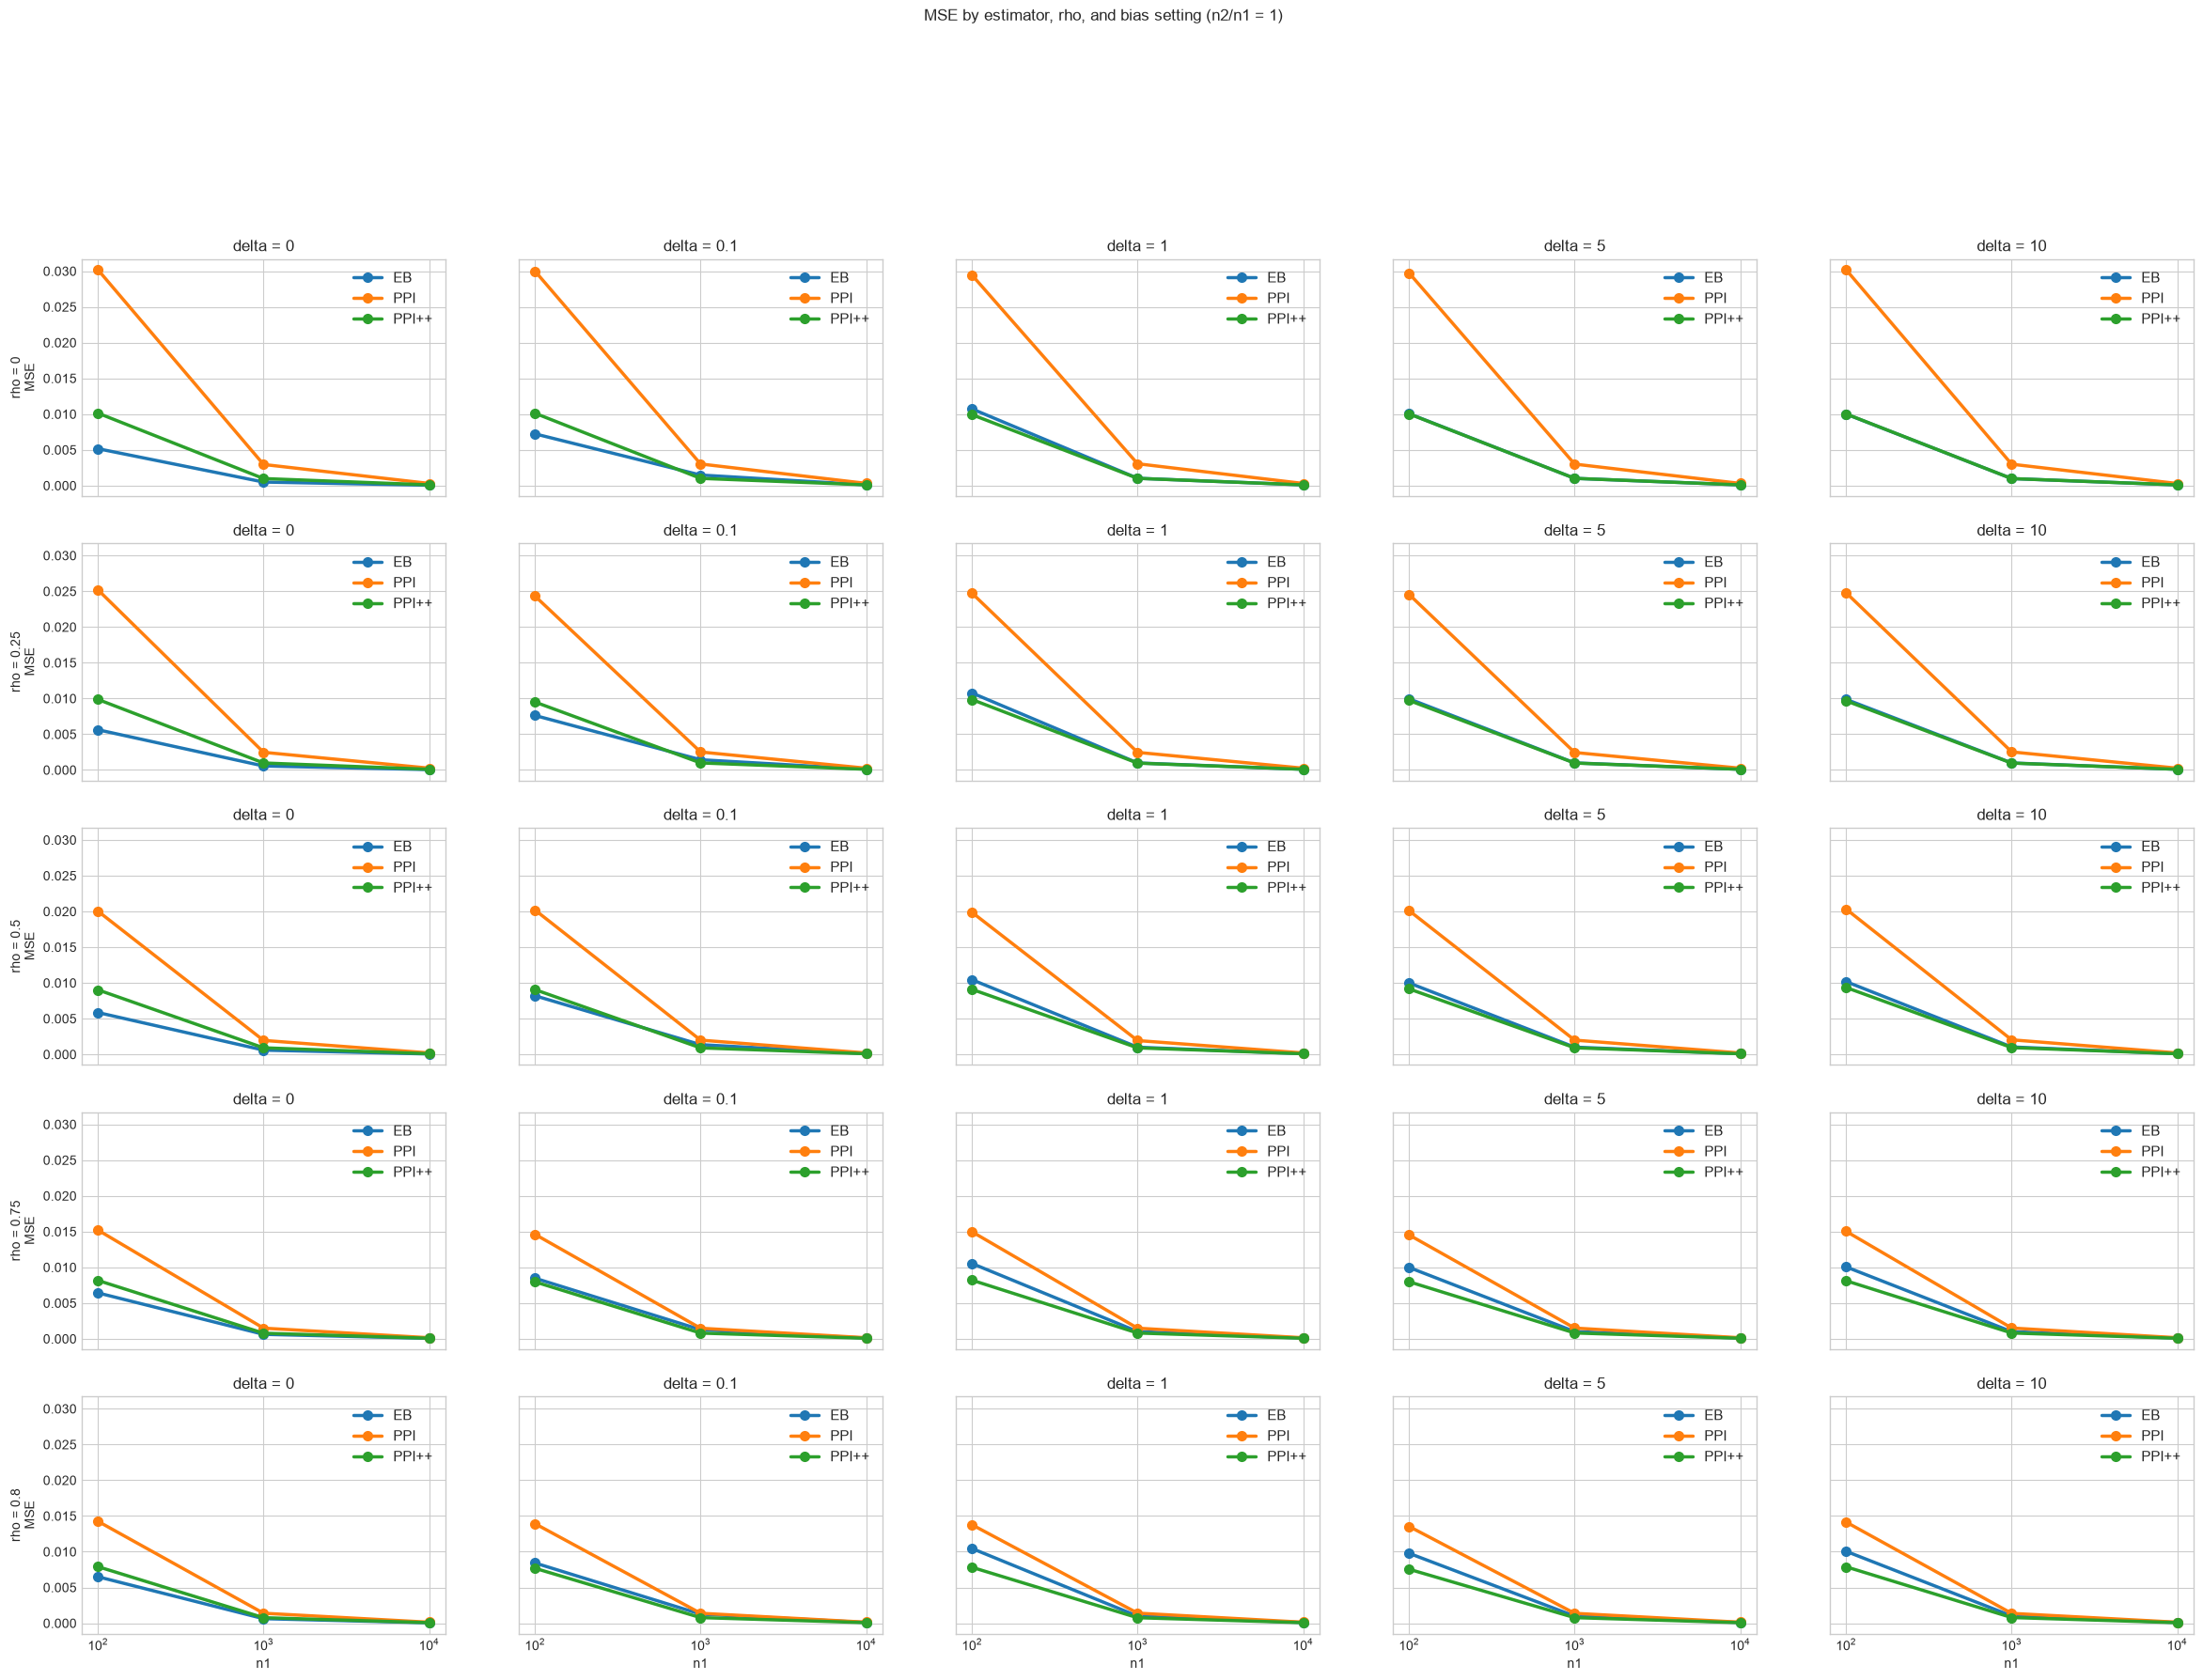

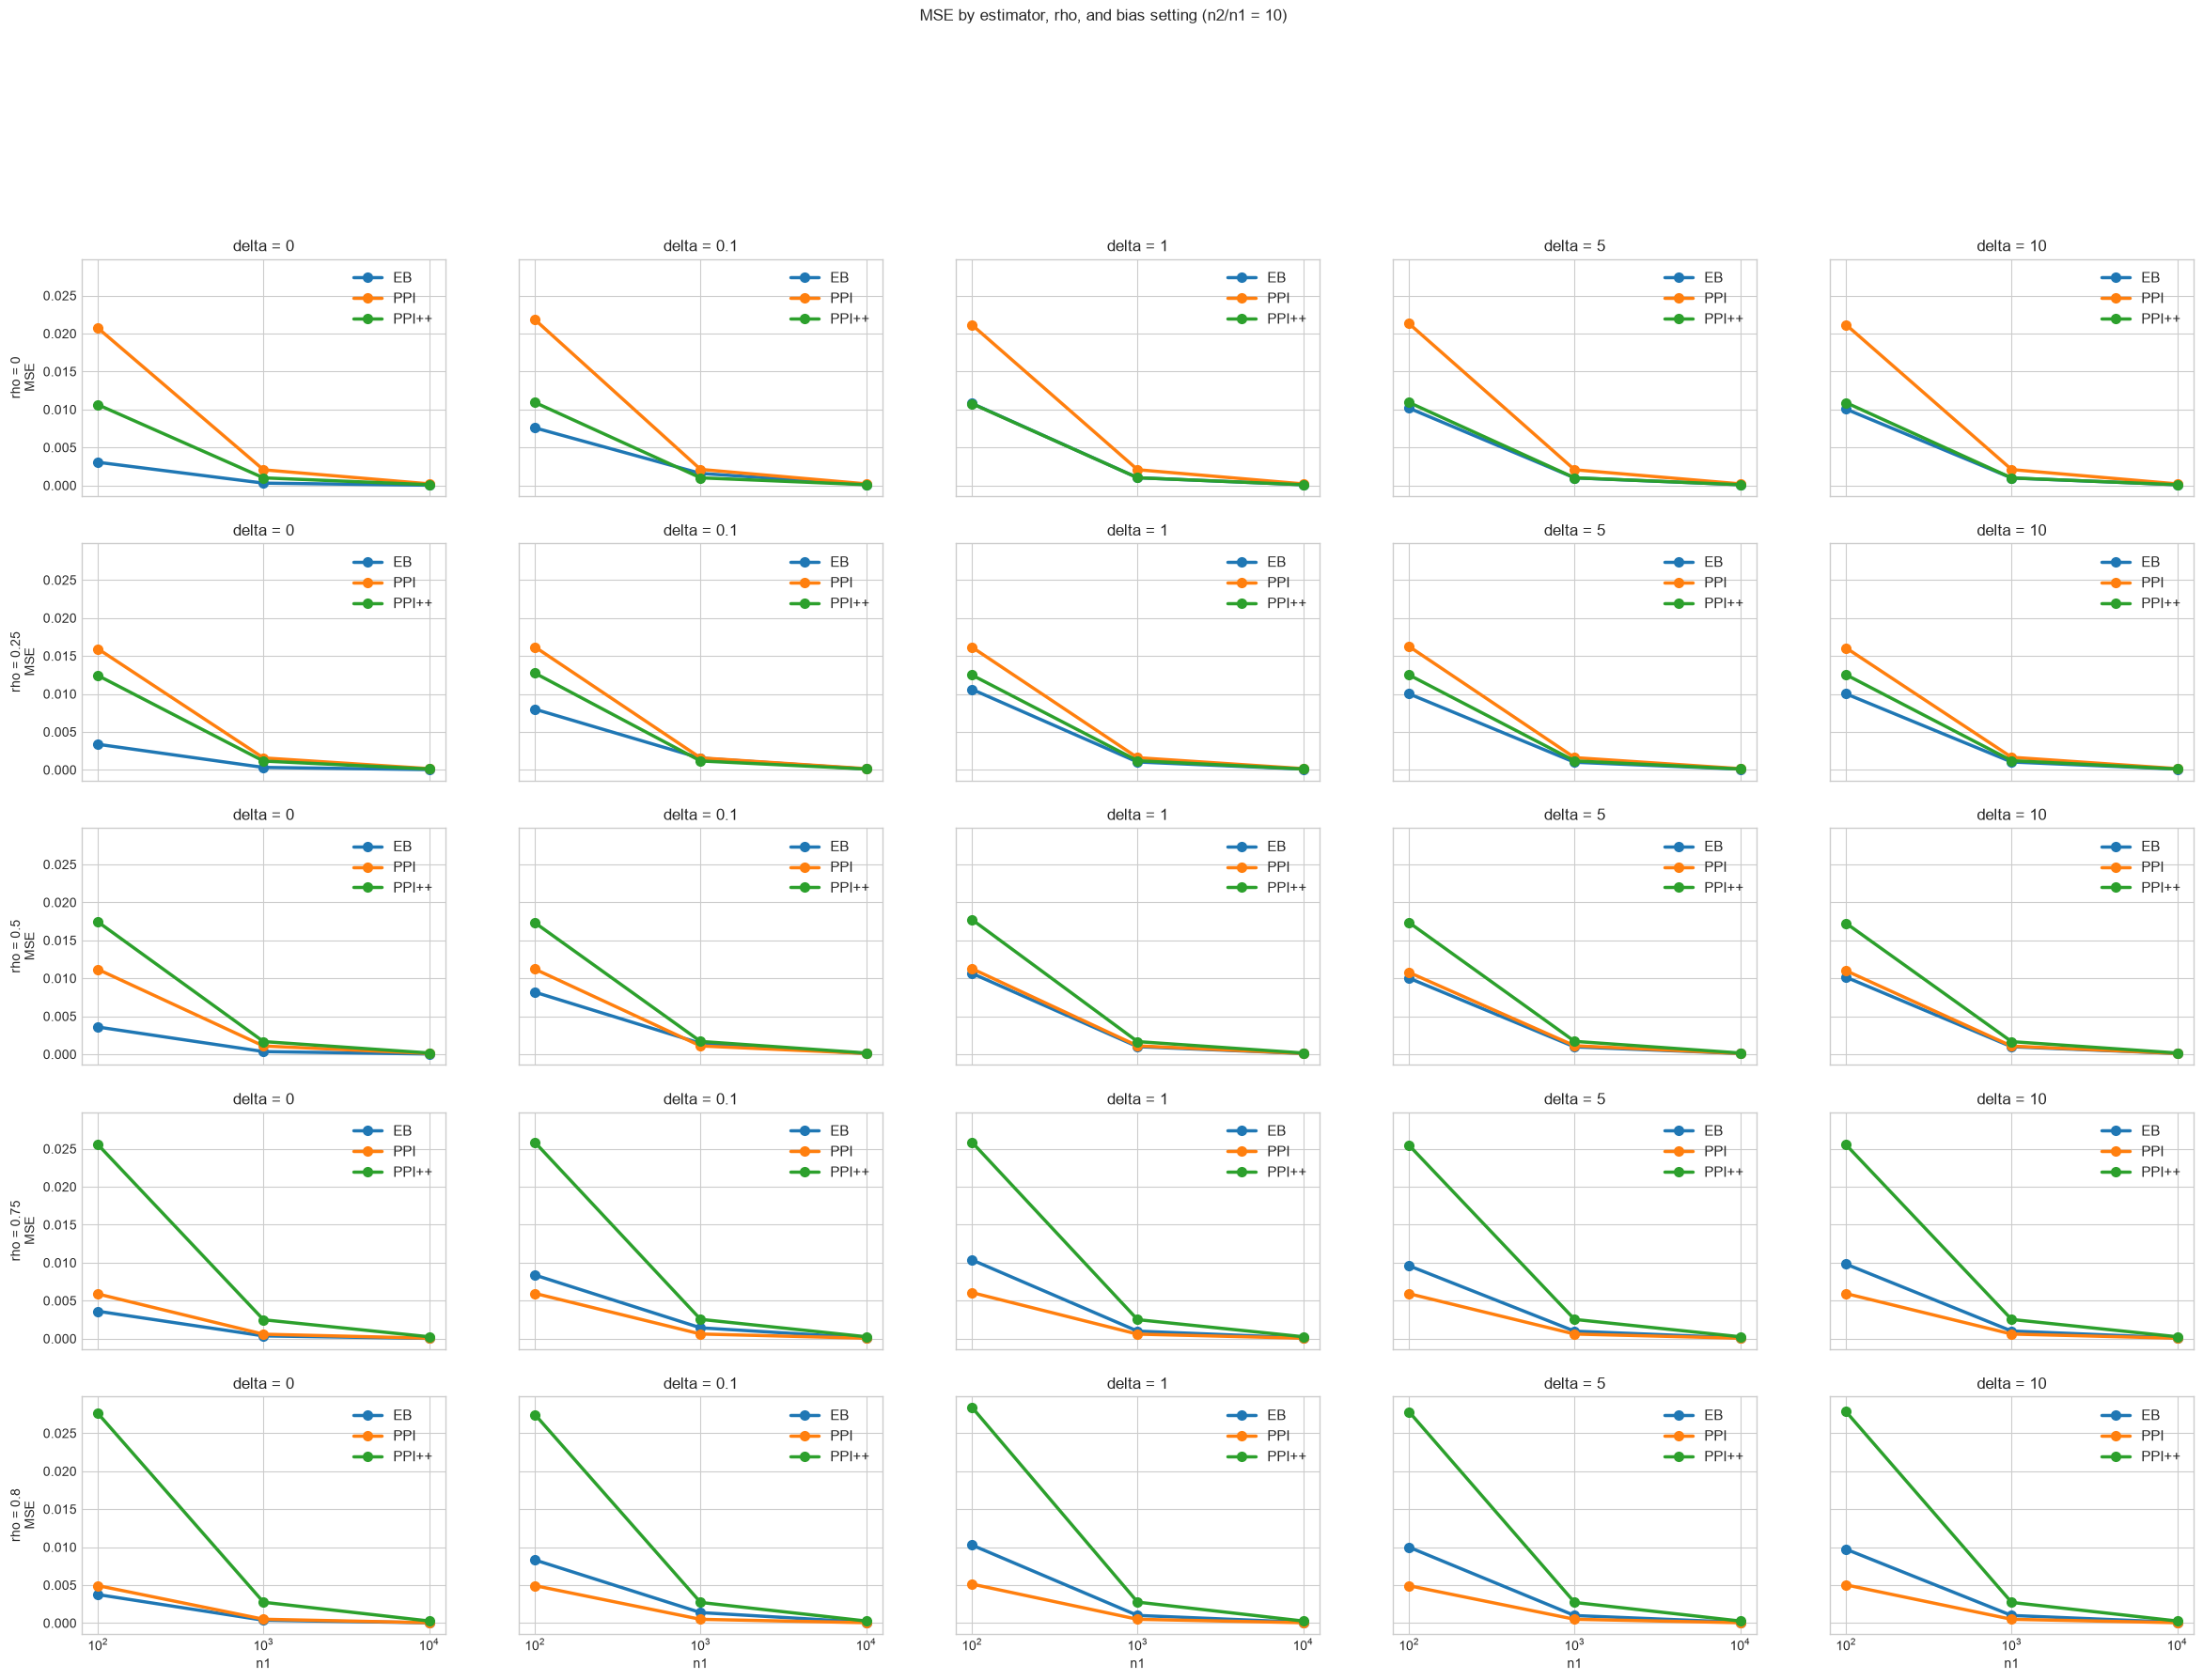

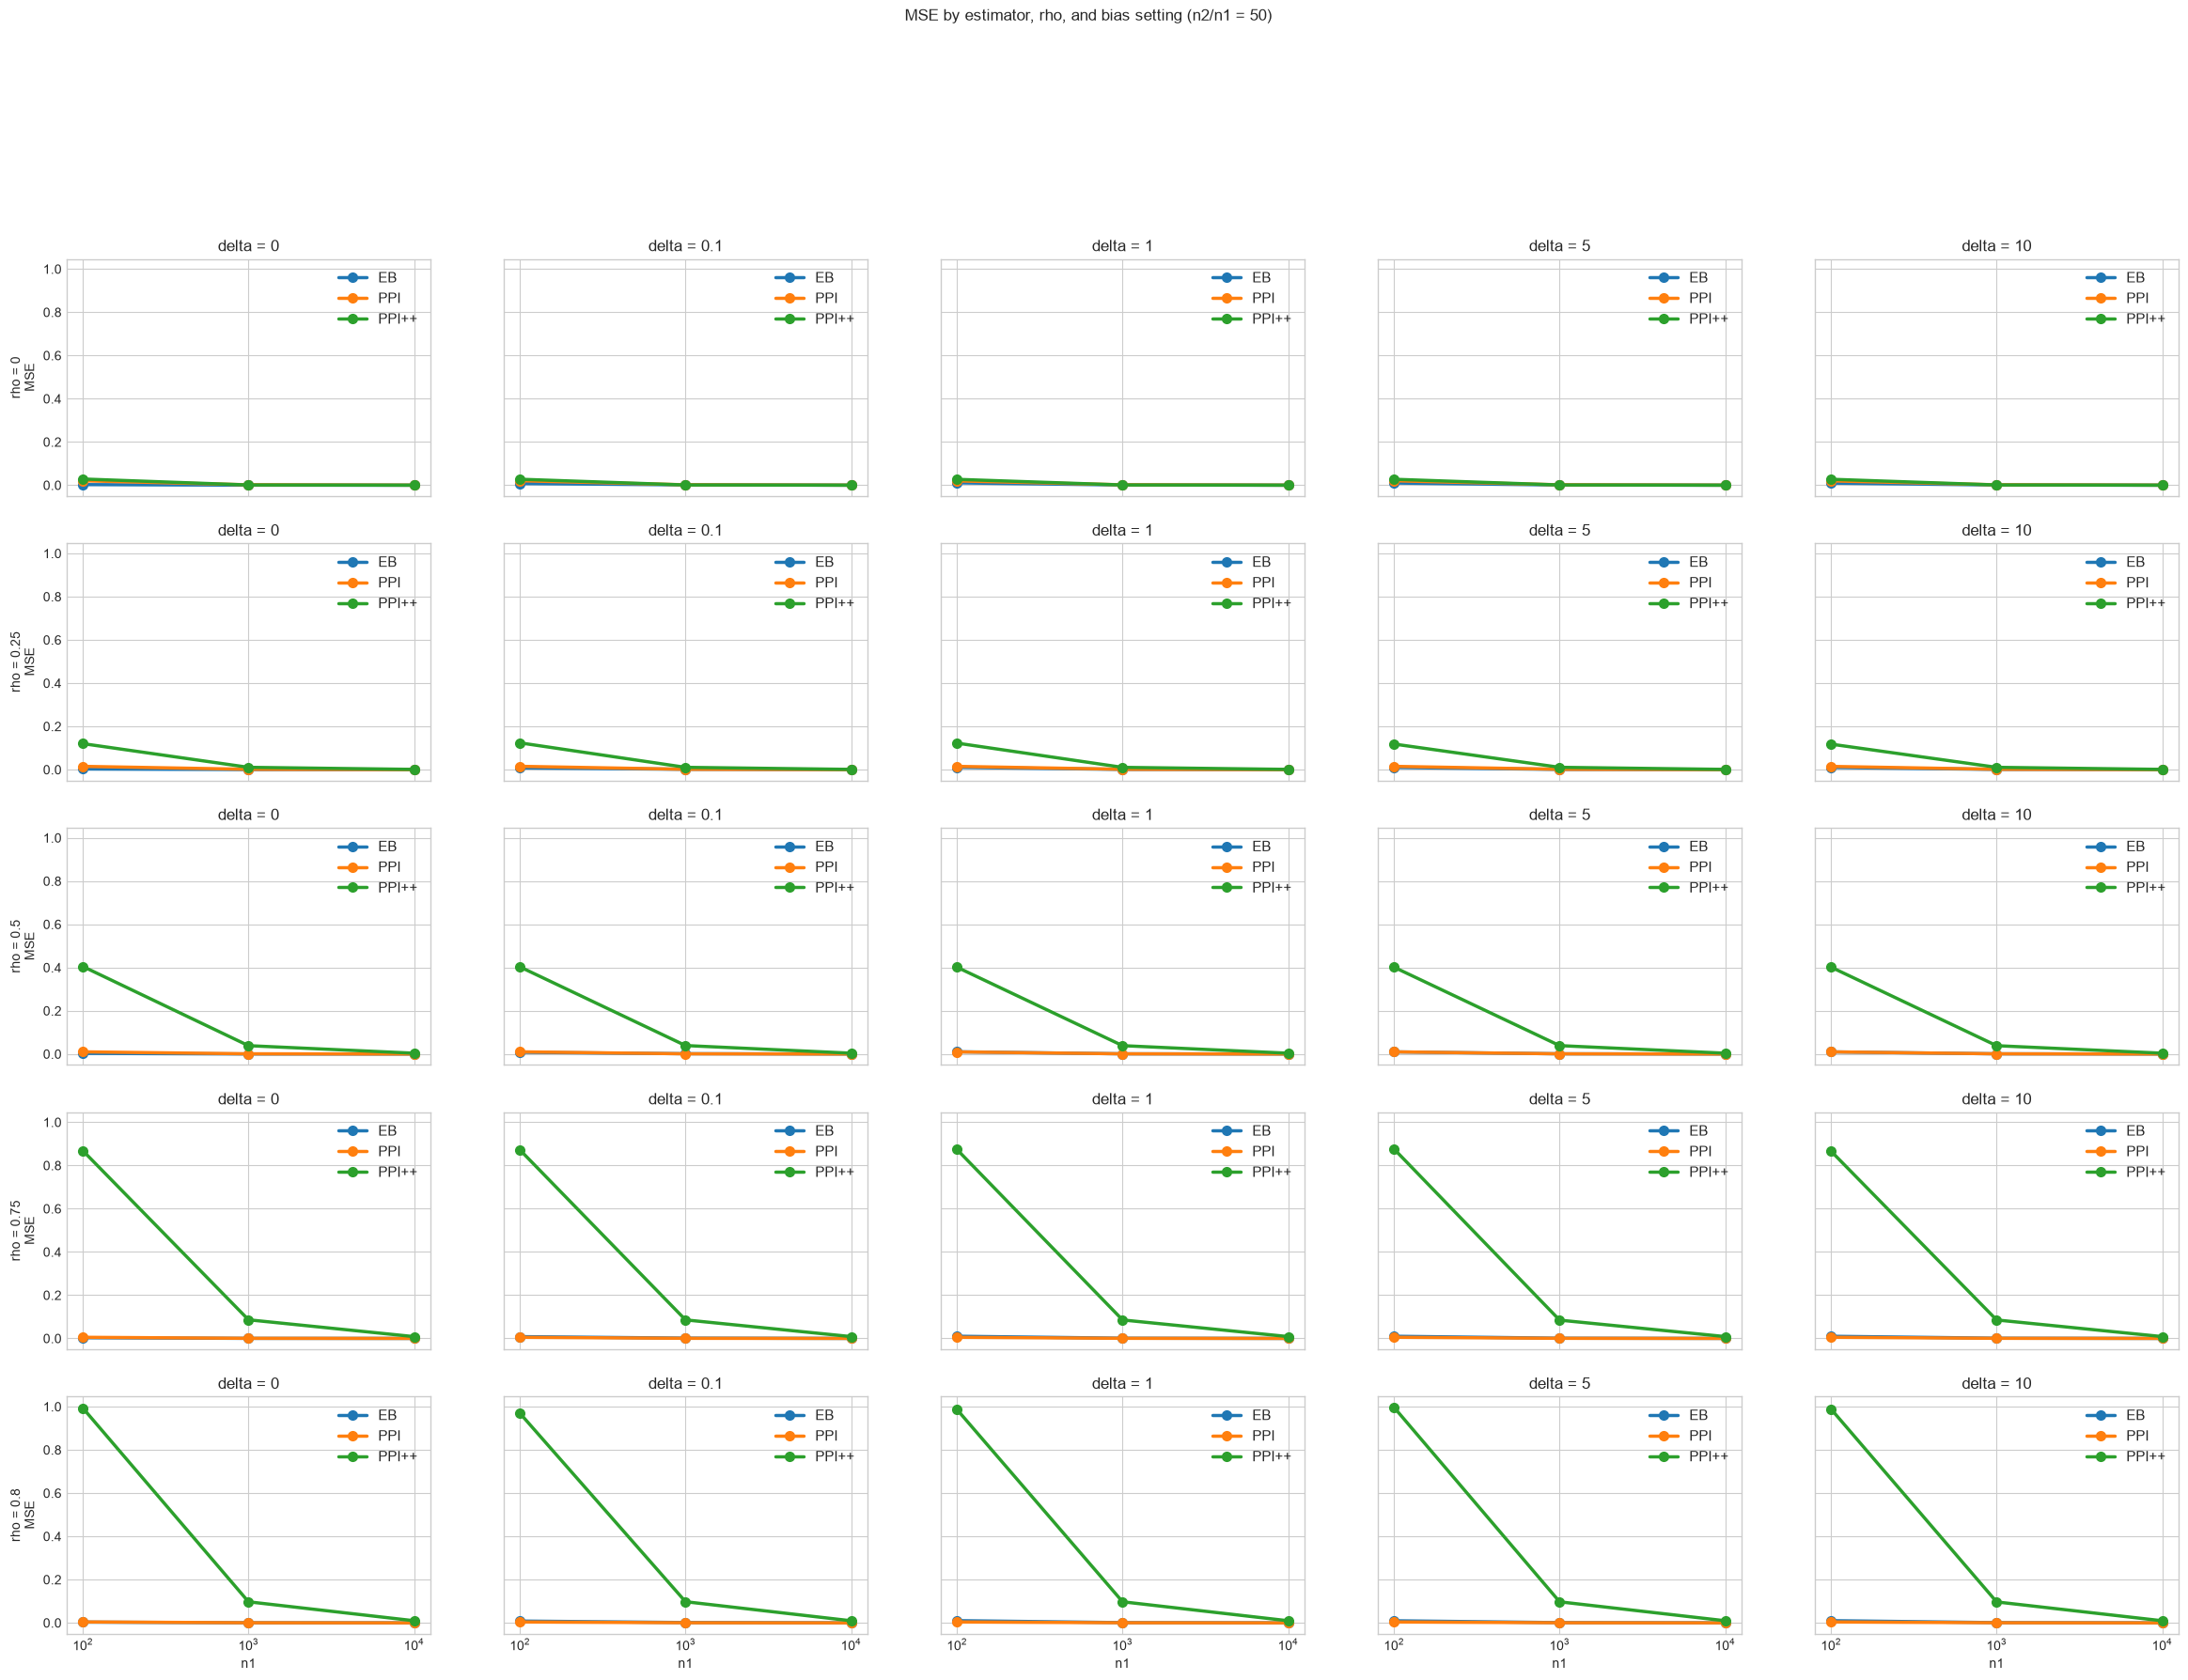

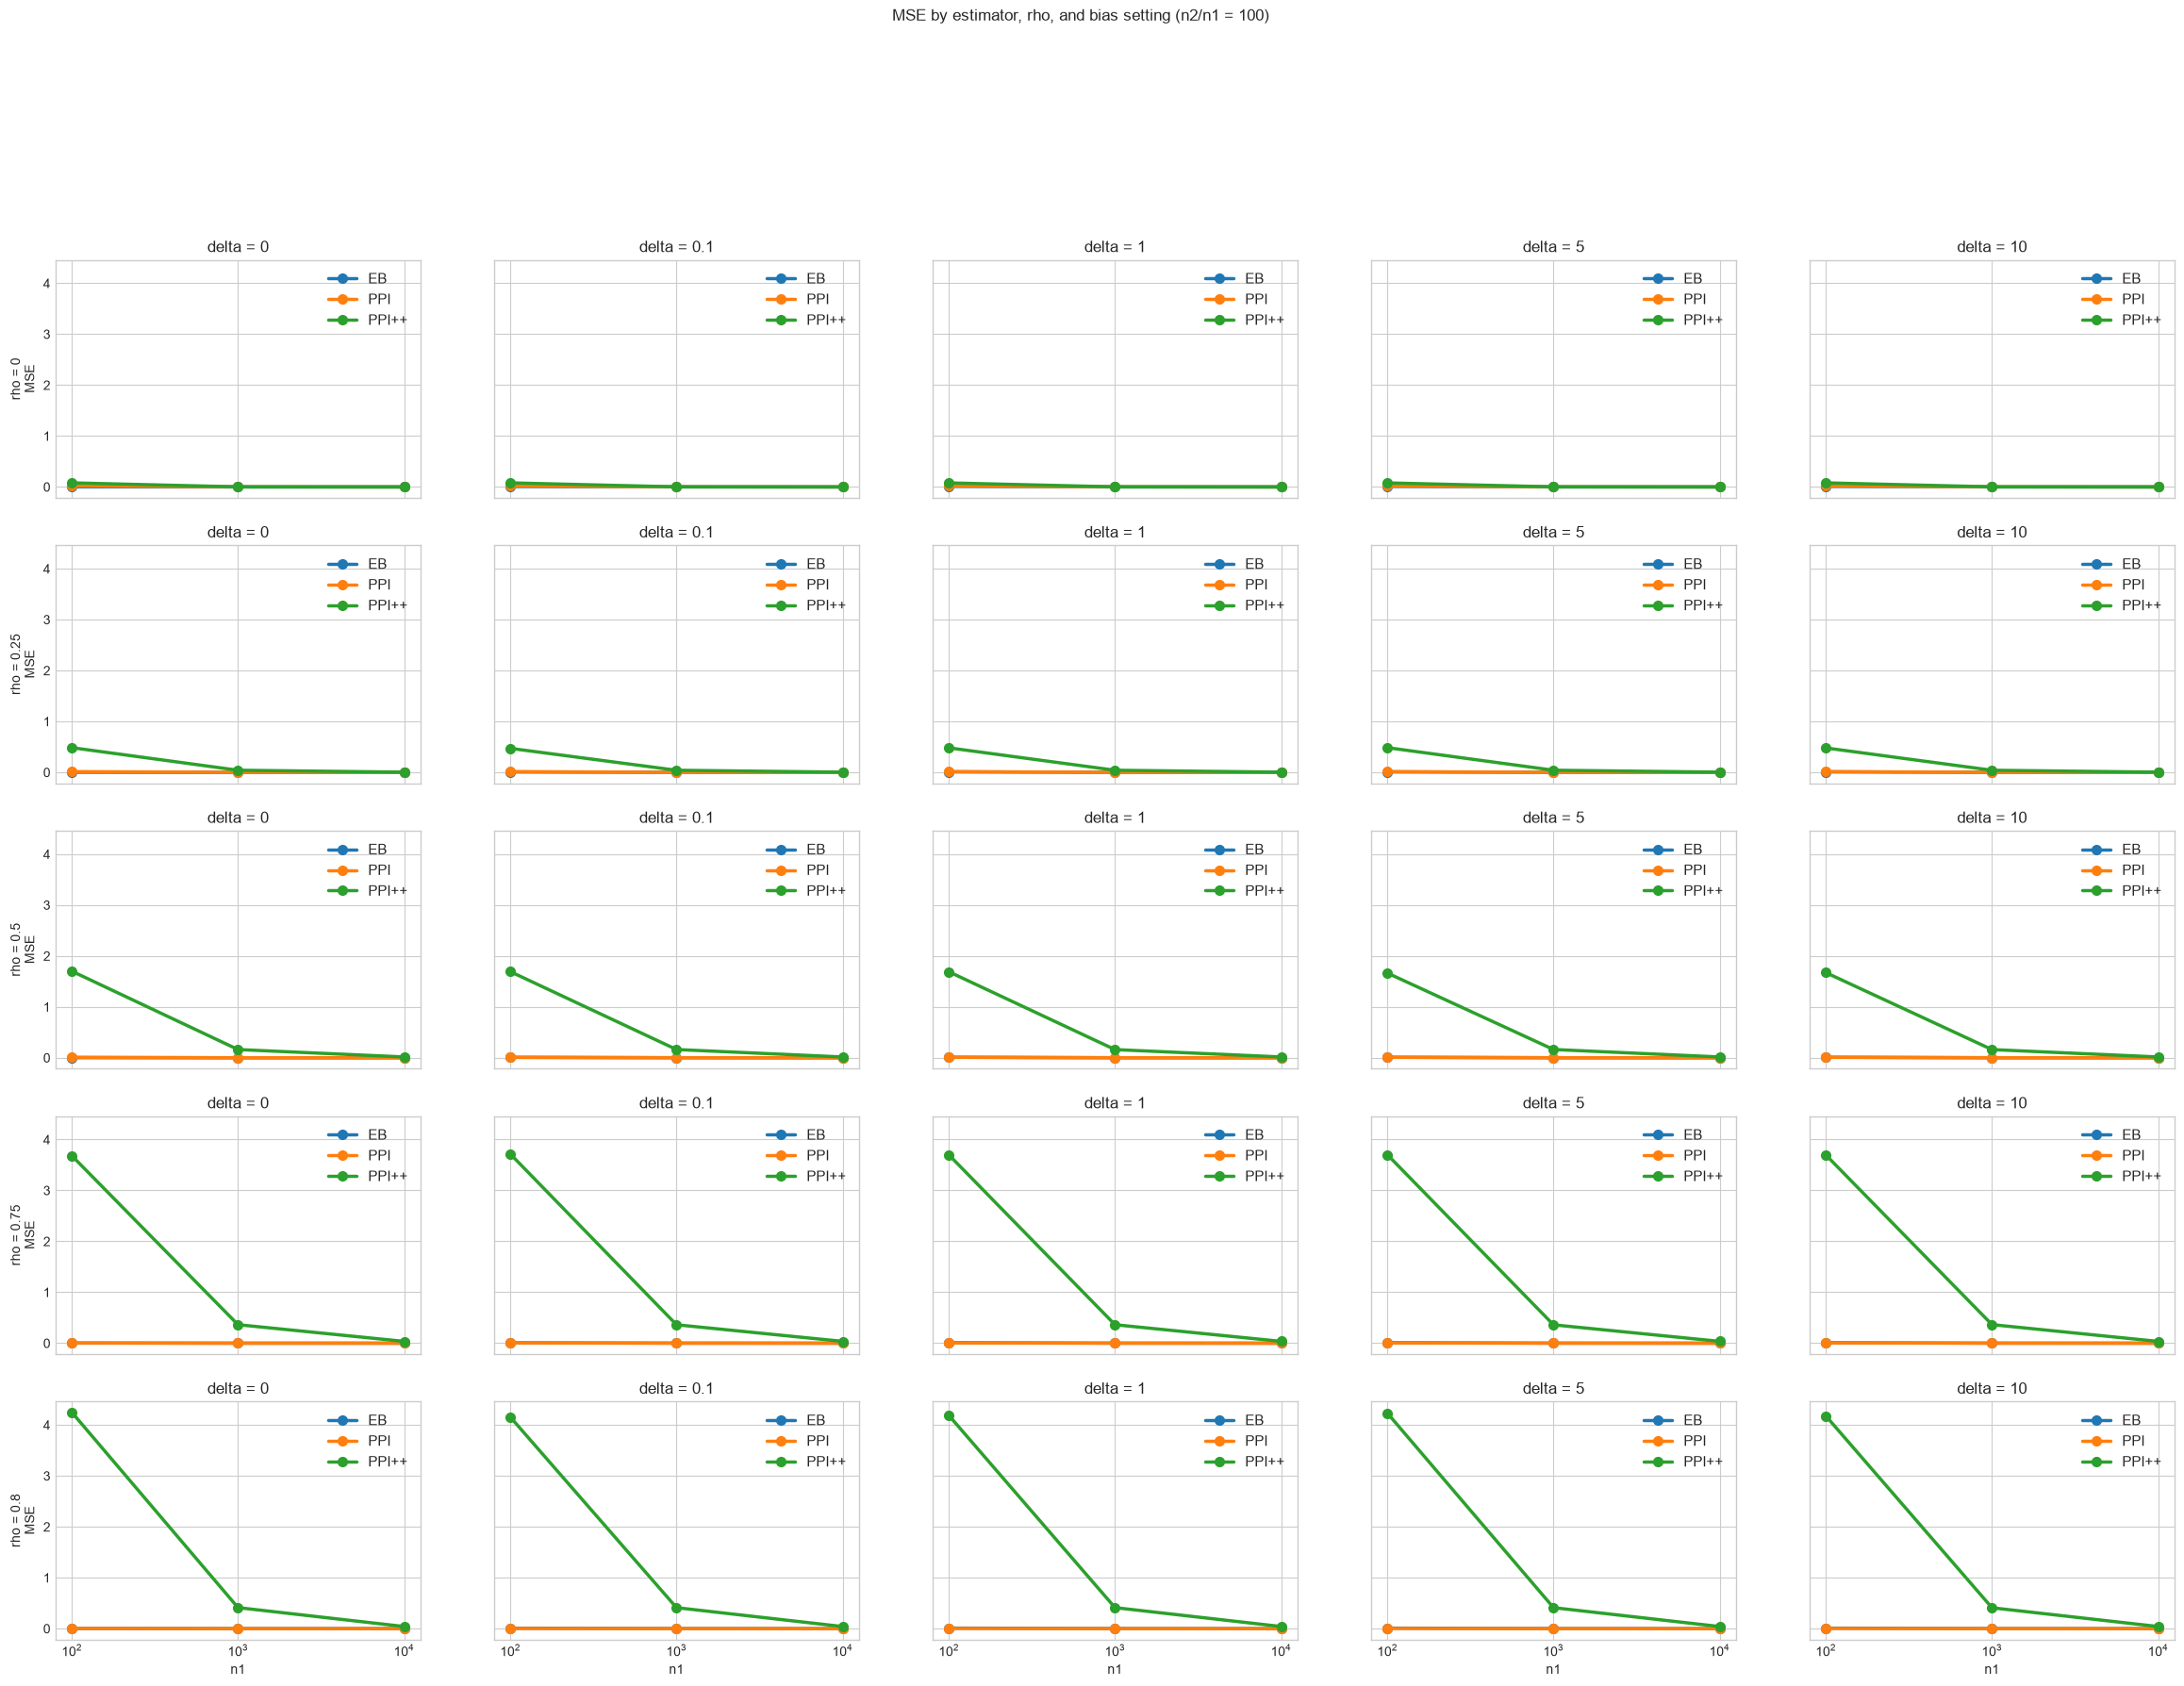

In [12]:
for multiplier in multipliers:
    selected = summary[summary['multiplier'] == multiplier]
    fig, axes = plt.subplots(
        len(rhos), len(deltas),
        figsize=(5.8 * len(deltas), 3.8 * len(rhos)),
        sharex=True, sharey=True, squeeze=False,
    )

    for row, rho in enumerate(rhos):
        for col, delta in enumerate(deltas):
            ax = axes[row, col]
            panel = selected[(selected['rho'] == rho) & (selected['delta'] == delta)]
            for method in methods:
                mse_column = f'{method}_mse'
                curve = panel.sort_values('n1')
                ax.plot(curve['n1'], curve[mse_column], marker='o',
                        linewidth=2.5, markersize=7, label=method_labels[method])
            ax.set_xscale('log')
            ax.set_title(f'delta = {delta:g}')
            if col == 0:
                ax.set_ylabel(f'rho = {rho:g}\nMSE')
            if row == len(rhos) - 1:
                ax.set_xlabel('n1')
            ax.legend(fontsize=11)

    fig.suptitle(f'MSE by estimator, rho, and bias setting (n2/n1 = {multiplier:g})', y=1.02)
    plt.show()
